<a href="https://colab.research.google.com/github/RealHotnCold/MLA0204-192511036/blob/main/13_Implement_the_Car_Price_Prediction_Model_using_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Car Price Prediction Model
This notebook demonstrates a complete end-to-end Machine Learning pipeline to predict car prices using Python, `pandas`, `scikit-learn`, and `seaborn` for visualization.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 1. Create Synthetic Dataset
We generate synthetic car data to simulate a realistic scenario.

In [2]:
np.random.seed(42)
n_samples = 1000

brands = ['Toyota', 'Honda', 'Ford', 'BMW', 'Audi']
fuel_types = ['Petrol', 'Diesel', 'Electric', 'Hybrid']

data = {
    'Brand': np.random.choice(brands, n_samples),
    'Year': np.random.randint(2010, 2024, n_samples),
    'Mileage': np.random.randint(5000, 150000, n_samples),
    'Fuel_Type': np.random.choice(fuel_types, n_samples),
    'Engine_Size': np.round(np.random.uniform(1.0, 4.0, n_samples), 1)
}

df = pd.DataFrame(data)

# Generate a logical price based on the features with some noise
base_price = 20000
brand_multiplier = df['Brand'].map({'Toyota': 1.0, 'Honda': 1.0, 'Ford': 0.9, 'BMW': 1.5, 'Audi': 1.6})
fuel_multiplier = df['Fuel_Type'].map({'Petrol': 1.0, 'Diesel': 1.1, 'Electric': 1.4, 'Hybrid': 1.25})
year_factor = (df['Year'] - 2010) * 1500
mileage_depreciation = df['Mileage'] * 0.12
engine_factor = df['Engine_Size'] * 3000

df['Price'] = (base_price + year_factor + engine_factor) * brand_multiplier * fuel_multiplier - mileage_depreciation
df['Price'] = df['Price'].clip(lower=2000) # Ensure no negative or unrealistically low prices
df['Price'] = np.round(df['Price'], 2)

display(df.head())

,Brand,Year,Mileage,Fuel_Type,Engine_Size,Price
0,BMW,2021,47229,Electric,3.1,90512.52
1,Audi,2021,91652,Hybrid,3.9,85401.76
2,Ford,2013,133267,Petrol,2.7,13347.96
3,Audi,2013,131503,Hybrid,1.8,44019.64
4,Audi,2014,89878,Hybrid,2.3,55014.64


## 2. Exploratory Data Analysis (EDA)
Let's visualize the relationship between key features and the Target Variable (`Price`).

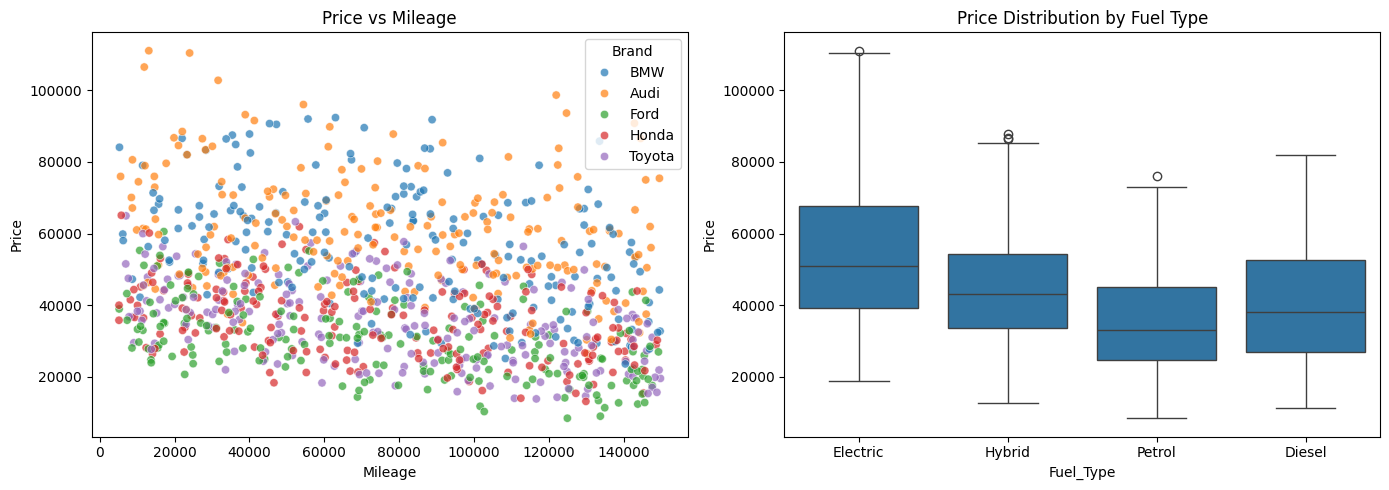

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df, x='Mileage', y='Price', hue='Brand', ax=axes[0], alpha=0.7)
axes[0].set_title('Price vs Mileage')

sns.boxplot(data=df, x='Fuel_Type', y='Price', ax=axes[1])
axes[1].set_title('Price Distribution by Fuel Type')

plt.tight_layout()
plt.show()

## 3. Data Splitting & Pipeline Building
We separate target from features, set up a pipeline to handle preprocessing (one-hot encoding categorical variables), and train a Random Forest Regressor.

In [4]:
X = df.drop('Price', axis=1)
y = df['Price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

categorical_features = ['Brand', 'Fuel_Type']
numeric_features = ['Year', 'Mileage', 'Engine_Size']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first'), categorical_features)
    ],
    remainder='passthrough'
)

model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
])

model_pipeline.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(drop='first'),
                                                  ['Brand', 'Fuel_Type'])])),
                ('regressor', RandomForestRegressor(random_state=42))])

## 4. Evaluation
Let's evaluate the model using R² score, Mean Absolute Error (MAE), and Root Mean Squared Error (RMSE).

R2 Score: 0.9620
Mean Absolute Error (MAE): $2535.23
Root Mean Squared Error (RMSE): $3273.30


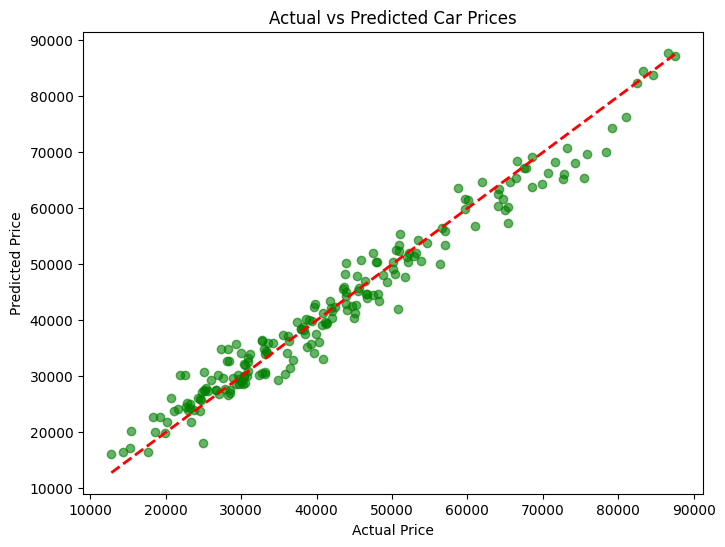

In [5]:
y_pred = model_pipeline.predict(X_test)

print(f"R2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Absolute Error (MAE): ${mean_absolute_error(y_test, y_pred):.2f}")
print(f"Root Mean Squared Error (RMSE): ${np.sqrt(mean_squared_error(y_test, y_pred)):.2f}")

# Plot True vs Predicted Prices
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color='g')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Car Prices')
plt.show()